# Практическая работа 1. Графы
Проверка ручных решений с помощью networkx

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

## Задача 1

Матрица смежности:
[[0 1 0 0 0]
 [0 0 1 1 0]
 [0 0 0 0 1]
 [0 0 0 0 1]
 [1 0 0 0 0]]
Рёбра: [(1, 2), (2, 3), (2, 4), (3, 5), (4, 5), (5, 1)]
Матрица инцидентности (-1 выходит, 1 входит):
[[-1  0  0  0  0  1]
 [ 1 -1 -1  0  0  0]
 [ 0  1  0 -1  0  0]
 [ 0  0  1  0 -1  0]
 [ 0  0  0  1  1 -1]]
Списки смежности:
1 : [2]
2 : [3, 4]
3 : [5]
4 : [5]
5 : [1]


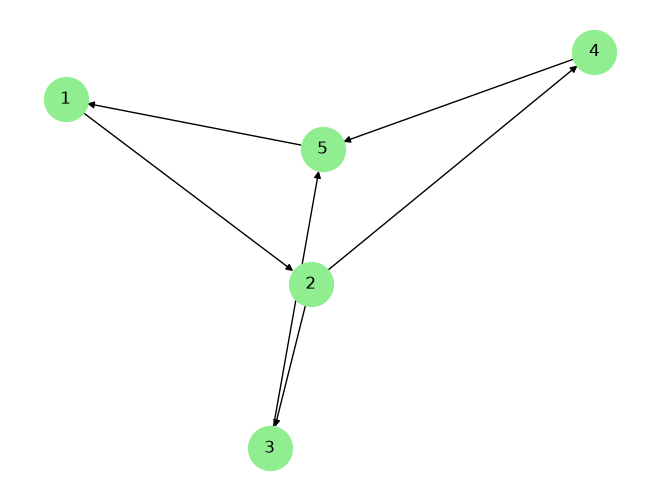

In [2]:
# ориентированный граф
G1 = nx.DiGraph()
G1.add_edges_from([(1, 2), (2, 3), (2, 4), (3, 5), (4, 5), (5, 1)])
nodes = [1, 2, 3, 4, 5]

print('Матрица смежности:')
print(nx.to_numpy_array(G1, nodelist=nodes).astype(int))
print('Рёбра:', list(G1.edges()))
print('Матрица инцидентности (-1 выходит, 1 входит):')
print(nx.incidence_matrix(G1, nodelist=nodes, edgelist=list(G1.edges()), oriented=True).toarray().astype(int))
print('Списки смежности:')
for v in nodes:
    print(v, ':', list(G1.successors(v)))

nx.draw(G1, with_labels=True, node_color='lightgreen', node_size=1000)
plt.show()

## Задача 2

Матрица смежности (с весами):
[[0 2 4 0]
 [2 0 1 3]
 [4 1 0 5]
 [0 3 5 0]]
Рёбра: [('X', 'Y'), ('X', 'Z'), ('Y', 'Z'), ('Y', 'W'), ('Z', 'W')]
Матрица инцидентности:
[[1 1 0 0 0]
 [1 0 1 1 0]
 [0 1 1 0 1]
 [0 0 0 1 1]]
Списки смежности:
X : [('Y', 2), ('Z', 4)]
Y : [('X', 2), ('Z', 1), ('W', 3)]
Z : [('X', 4), ('Y', 1), ('W', 5)]
W : [('Y', 3), ('Z', 5)]


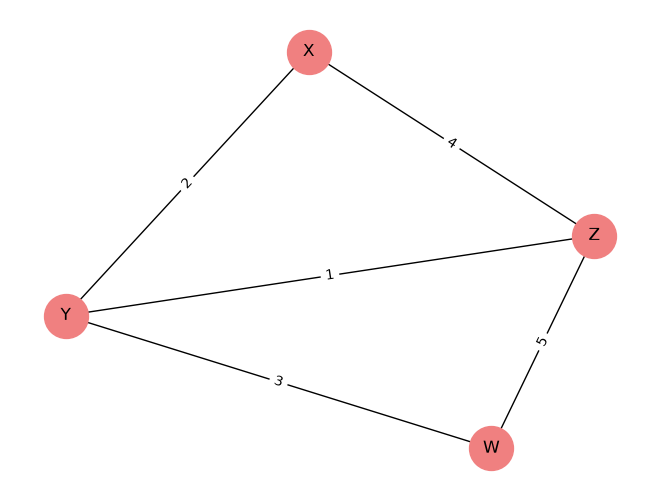

In [3]:
# взвешенный граф
G2 = nx.Graph()
G2.add_weighted_edges_from([('X', 'Y', 2), ('X', 'Z', 4), ('Y', 'Z', 1), ('Y', 'W', 3), ('Z', 'W', 5)])
nodes = ['X', 'Y', 'Z', 'W']

print('Матрица смежности (с весами):')
print(nx.to_numpy_array(G2, nodelist=nodes).astype(int))
print('Рёбра:', list(G2.edges()))
print('Матрица инцидентности:')
print(nx.incidence_matrix(G2, nodelist=nodes, edgelist=list(G2.edges())).toarray().astype(int))
print('Списки смежности:')
for v in nodes:
    print(v, ':', [(u, G2[v][u]['weight']) for u in G2.neighbors(v)])

pos = nx.spring_layout(G2, seed=1)
nx.draw(G2, pos, with_labels=True, node_color='lightcoral', node_size=1000)
nx.draw_networkx_edge_labels(G2, pos, edge_labels=nx.get_edge_attributes(G2, 'weight'))
plt.show()

## Задачи 3-5 (эйлеровы циклы)

In [4]:
def check_euler(edges):
    G = nx.Graph()
    G.add_edges_from(edges)
    print('Степени вершин:', dict(sorted(G.degree())))
    print('Граф эйлеров:', nx.is_eulerian(G))
    return G


def check_cycle(G, cycle):
    # проверяем, что цикл проходит каждое ребро ровно один раз
    used = set()
    for i in range(len(cycle) - 1):
        e = frozenset((cycle[i], cycle[i + 1]))
        if not G.has_edge(cycle[i], cycle[i + 1]) or e in used:
            return False
        used.add(e)
    return len(used) == G.number_of_edges() and cycle[0] == cycle[-1]

Степени вершин: {1: 4, 2: 4, 3: 4, 4: 4, 5: 4, 6: 4}
Граф эйлеров: True
Мой цикл [1, 2, 3, 1, 5, 3, 4, 5, 6, 4, 2, 6, 1] верный: True


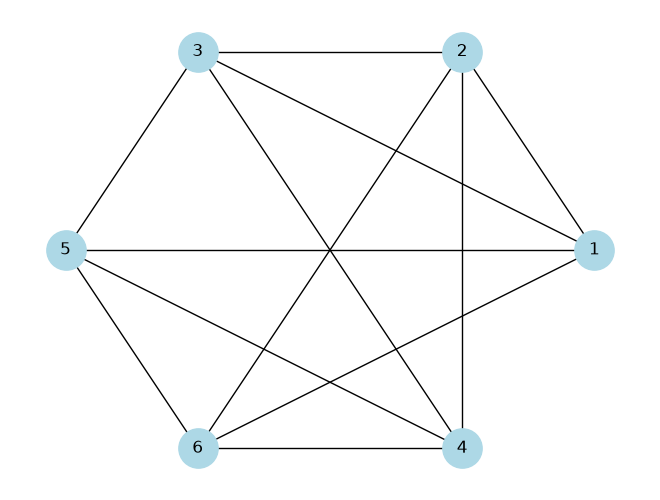

In [5]:
E3 = [(1, 2), (1, 3), (1, 5), (1, 6), (2, 3), (2, 4), (2, 6), (3, 4), (3, 5), (4, 5), (4, 6), (5, 6)]
G3 = check_euler(E3)
c3 = [1, 2, 3, 1, 5, 3, 4, 5, 6, 4, 2, 6, 1]
print('Мой цикл', c3, 'верный:', check_cycle(G3, c3))
nx.draw_circular(G3, with_labels=True, node_color='lightblue', node_size=800)
plt.show()

Степени вершин: {1: 4, 2: 2, 3: 4, 4: 4, 5: 2, 6: 2, 7: 4}
Граф эйлеров: True
Мой цикл [1, 4, 2, 7, 1, 5, 3, 4, 7, 3, 6, 1] верный: True


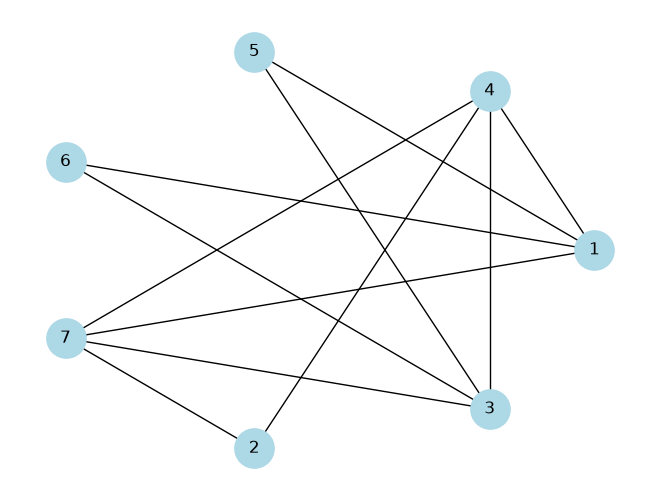

In [6]:
E4 = [(1, 4), (1, 5), (1, 6), (1, 7), (2, 4), (2, 7), (3, 4), (3, 5), (3, 6), (3, 7), (4, 7)]
G4 = check_euler(E4)
c4 = [1, 4, 2, 7, 1, 5, 3, 4, 7, 3, 6, 1]
print('Мой цикл', c4, 'верный:', check_cycle(G4, c4))
nx.draw_circular(G4, with_labels=True, node_color='lightblue', node_size=800)
plt.show()

Степени вершин: {1: 2, 2: 2, 3: 4, 4: 4, 5: 2, 6: 4, 7: 2, 8: 4}
Граф эйлеров: True
Мой цикл [1, 6, 2, 7, 8, 3, 4, 5, 3, 6, 4, 8, 1] верный: True


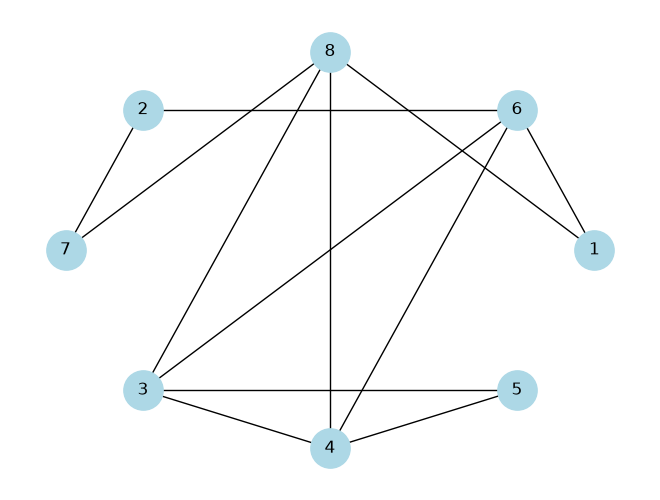

In [7]:
E5 = [(1, 6), (1, 8), (2, 6), (2, 7), (3, 4), (3, 5), (3, 6), (3, 8), (4, 5), (4, 6), (4, 8), (7, 8)]
G5 = check_euler(E5)
c5 = [1, 6, 2, 7, 8, 3, 4, 5, 3, 6, 4, 8, 1]
print('Мой цикл', c5, 'верный:', check_cycle(G5, c5))
nx.draw_circular(G5, with_labels=True, node_color='lightblue', node_size=800)
plt.show()

## Задача 6

In [8]:
G6 = nx.DiGraph()
G6.add_edges_from([('A', 'B'), ('A', 'C'), ('B', 'D'), ('C', 'D'), ('C', 'E'), ('D', 'E'), ('D', 'F'), ('E', 'F')])
for p in nx.all_simple_paths(G6, 'A', 'F'):
    print(' -> '.join(p), ' рёбер:', len(p) - 1)
print('Циклы в графе:', list(nx.simple_cycles(G6)))

A -> B -> D -> E -> F  рёбер: 4
A -> B -> D -> F  рёбер: 3
A -> C -> D -> E -> F  рёбер: 4
A -> C -> D -> F  рёбер: 3
A -> C -> E -> F  рёбер: 3
Циклы в графе: []


## Задача 7

In [9]:
G7 = nx.Graph()
G7.add_edges_from([(1, 2), (1, 3), (2, 4), (2, 5), (3, 5), (4, 6), (5, 6), (5, 7), (6, 7)])
paths = list(nx.all_simple_paths(G7, 1, 7))
paths.sort(key=len)
for p in paths:
    print(p, ' рёбер:', len(p) - 1)
print('Всего простых маршрутов:', len(paths))
print('Кратчайшие:', list(nx.all_shortest_paths(G7, 1, 7)))

[1, 2, 5, 7]  рёбер: 3
[1, 3, 5, 7]  рёбер: 3
[1, 2, 4, 6, 7]  рёбер: 4
[1, 2, 5, 6, 7]  рёбер: 4
[1, 3, 5, 6, 7]  рёбер: 4
[1, 2, 4, 6, 5, 7]  рёбер: 5
[1, 3, 5, 2, 4, 6, 7]  рёбер: 6
Всего простых маршрутов: 7
Кратчайшие: [[1, 2, 5, 7], [1, 3, 5, 7]]
